## Exploring the Comment data

In [1]:
import pandas as pd

df = pd.read_parquet("../data/AWS PTS Reviews/issues_parquet/output_1.parquet")

print(df.shape)
print(df.dtypes)
df.head()

(500000, 12)
REVIEW_ID                   int64
REVIEW_CYCLE_ID             int64
DISCIPLINE                    str
STATUS                        str
DUE_DT             datetime64[ns]
COMPLETE_DT        datetime64[ns]
ISSUE_NUM                   int64
ISSUE_TEXT                    str
IS_CLEARED_IND                str
CLEARED_DT         datetime64[ns]
PROJ_ID                     int64
SCOPE                         str
dtype: object


,REVIEW_ID,REVIEW_CYCLE_ID,DISCIPLINE,STATUS,DUE_DT,COMPLETE_DT,ISSUE_NUM,ISSUE_TEXT,IS_CLEARED_IND,CLEARED_DT,PROJ_ID,SCOPE
0,1142,266,LDR-Engineering Review,Closed,2001-09-10,2001-09-06 09:05:24,1,"On the site and grading plans, move the propos...",N,NaT,1279,41-0458 CDP/VAR (Process 3) to demolish two s...
1,1142,266,LDR-Engineering Review,Closed,2001-09-10,2001-09-06 09:05:24,2,"Prior to the issuance of any building permits,...",N,NaT,1279,41-0458 CDP/VAR (Process 3) to demolish two s...
2,2405,517,BDR-Structural,Assignment Pending,NaT,NaT,1,These structural comments are for the prelimin...,N,NaT,1371,* [9/10/01] PRELIMINARY REVIEW MEETING FOR...
3,2405,517,BDR-Structural,Assignment Pending,NaT,NaT,2,Exit enclosures must extend to the exterior of...,N,NaT,1371,* [9/10/01] PRELIMINARY REVIEW MEETING FOR...
4,2405,517,BDR-Structural,Assignment Pending,NaT,NaT,3,The two stairs enclosures are not one-half the...,N,NaT,1371,* [9/10/01] PRELIMINARY REVIEW MEETING FOR...


In [2]:
df["STATUS"].value_counts()

STATUS
Closed                436623
Cancelled              48850
Assignment Pending     13654
Completed                864
Started                    5
Assigned                   4
Name: count, dtype: int64

## Patterns in permit review comments (exploratory, preliminary)

**Goal.** DSD reviewers leave written comments on plans ("issues"). If many comments repeat, or fall into a few themes, those themes are candidates for fixes: clearer checklists, better guidance for applicants, or templates. This notebook asks two questions:

1. Do many *similar* comments show up for each type of permit?
2. Which themes show up most, and where do they concentrate (which review discipline, which permit type)?

**Data.** Review comments pulled from DSD's P2K system (`data/AWS PTS Reviews/issues_parquet/`, 33 chunks of one result set, 16.5 million comments). **One row = one review comment.** Review-level and project-level columns (discipline, dates, project scope) repeat on every comment of that review.

**Read this first.**
- We load **all 33 chunks** (`N_FILES = 33` at the top; lower it for a quick test run). The clustering step is the one place we cut corners to keep memory in check: see section 4. Everything is still exploratory.
- The data is raw and unvalidated. Results are preliminary and are not official City or DSD findings.
- Example comments are verbatim reviewer text (phone numbers, emails, and names written right next to them are masked where we could detect them, but names can still slip through). Check the outputs before sharing this notebook outside the team.

**Methods (only two, on purpose).** (1) Exact and near-exact matching after cleaning up the text, which shows boilerplate. (2) TF-IDF plus KMeans clustering, which groups comments by similar wording.

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

# Find the repo root whether the notebook runs from the root or notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
PARQUET_DIR = DATA / "AWS PTS Reviews" / "issues_parquet"

N_FILES = 33     # how many parquet chunks to load (33 exist = all of them)
MIN_YEAR = 2010  # keep review comments from this year on (see step 2 for why)
SEED = 0         # fixed so the clusters are reproducible
BLUE = "#2a78d6"

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)

## 1. Load and inspect

We load the first `N_FILES` parquet chunks (sorted by the number in the file name, so `output_2` comes before `output_10`), stack them, and drop rows that are exact duplicates.

In [4]:
files = sorted(PARQUET_DIR.glob("output_*.parquet"), key=lambda p: int(p.stem.split("_")[1]))
raw = pd.concat([pd.read_parquet(f) for f in files[:N_FILES]], ignore_index=True)
issues = raw.drop_duplicates().reset_index(drop=True)
n_raw = len(raw)
del raw   # free memory: 33 files are about 16.5M rows

print(f"Loaded {N_FILES} of {len(files)} files: {[f.name for f in files[:N_FILES]]}")
print(f"Rows: {n_raw:,} -> {len(issues):,} after dropping exact duplicates")

Loaded 33 of 33 files: ['output_1.parquet', 'output_2.parquet', 'output_3.parquet', 'output_4.parquet', 'output_5.parquet', 'output_6.parquet', 'output_7.parquet', 'output_8.parquet', 'output_9.parquet', 'output_10.parquet', 'output_11.parquet', 'output_12.parquet', 'output_13.parquet', 'output_14.parquet', 'output_15.parquet', 'output_16.parquet', 'output_17.parquet', 'output_18.parquet', 'output_19.parquet', 'output_20.parquet', 'output_21.parquet', 'output_22.parquet', 'output_23.parquet', 'output_24.parquet', 'output_25.parquet', 'output_26.parquet', 'output_27.parquet', 'output_28.parquet', 'output_29.parquet', 'output_30.parquet', 'output_31.parquet', 'output_32.parquet', 'output_33.parquet']
Rows: 16,493,872 -> 16,493,847 after dropping exact duplicates


Next, the shape, column types, and how much of each column is missing.

In [5]:
print("Shape:", issues.shape)
pd.DataFrame({"dtype": issues.dtypes.astype(str), "null_rate": issues.isna().mean().round(3)})

Shape: (16493847, 12)


,dtype,null_rate
REVIEW_ID,int64,0.000
REVIEW_CYCLE_ID,int64,0.000
DISCIPLINE,str,0.000
STATUS,str,0.000
DUE_DT,datetime64[ns],0.113
COMPLETE_DT,datetime64[ns],0.121
ISSUE_NUM,int64,0.000
ISSUE_TEXT,str,0.000
IS_CLEARED_IND,str,0.000
CLEARED_DT,datetime64[ns],0.619


**What this means.** The 33 files hold 16,493,872 comments and only 25 are exact duplicates. Comment text, discipline, and project ID are essentially always filled in. The gaps come from reviews that never finished: `DUE_DT` is blank on 11% of rows and `COMPLETE_DT` on 12%, and `CLEARED_DT` is blank on 62% because most comments were never marked cleared (checked below). `SCOPE` is missing for only 372 projects.

Now the date range. Review dates go back a long way, so we need to know how far.

In [6]:
for col in ["DUE_DT", "COMPLETE_DT", "CLEARED_DT"]:
    print(f"{col}: {issues[col].min():%Y-%m-%d} to {issues[col].max():%Y-%m-%d}")

DUE_DT: 2001-07-20 to 2026-07-15
COMPLETE_DT: 2001-07-23 to 2026-07-02
CLEARED_DT: 2001-07-23 to 2026-07-03


**What this means.** The data covers about 25 years, from July 2001 to July 2026. Forms, codes, and review practices change over that long a span, so we check below whether the old comments look different from recent ones.

Some comments have no text, so there is nothing to analyze: we drop those. We also add a `year` column (the year the review was completed, or due if it was never completed) so we can look at trends and, later, filter out old data.

In [7]:
empty = issues["ISSUE_TEXT"].isna() | (issues["ISSUE_TEXT"].str.strip() == "")
print(f"Dropping {empty.sum():,} rows with null or blank ISSUE_TEXT ({empty.mean():.2%})")
issues = issues[~empty].copy()

issues["year"] = issues["COMPLETE_DT"].dt.year.fillna(issues["DUE_DT"].dt.year).astype("Int64")
print(f"Rows left: {len(issues):,} | rows with no year (no completion or due date): {issues['year'].isna().sum():,}")

Dropping 4,809 rows with null or blank ISSUE_TEXT (0.03%)


Rows left: 16,489,038 | rows with no year (no completion or due date): 1,850,107


Row counts per discipline (a discipline is a reviewing group, such as structural or drainage) and per year.

In [8]:
print(issues["DISCIPLINE"].nunique(), "disciplines. Top 15 by number of comments:")
issues["DISCIPLINE"].value_counts().head(15).to_frame("comments").assign(pct=lambda d: (d["comments"] / len(issues) * 100).round(1))

160 disciplines. Top 15 by number of comments:


,comments,pct
DISCIPLINE,,
BDR-Structural,5325841,32.3
IAS-Combined Review,1870247,11.3
LDR-Drainage & Grades,1189098,7.2
BDR-Mechanical,1065869,6.5
LDR-Planning Review,643047,3.9
LDR-Eng Building Review,601614,3.6
LDR-Engineering Review,556464,3.4
BDR-Electrical,444667,2.7
Plan-Historic,364863,2.2


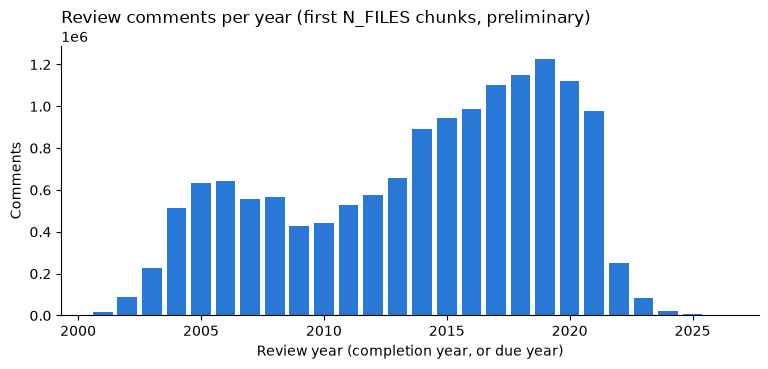

In [9]:
per_year = issues["year"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(per_year.index.astype(int), per_year.values, color=BLUE)
ax.set_xlabel("Review year (completion year, or due year)")
ax.set_ylabel("Comments")
ax.set_title("Review comments per year (first N_FILES chunks, preliminary)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**What this means.**
- **Discipline:** three groups write half of all comments: BDR-Structural (32%), IAS-Combined Review (11%), and LDR-Drainage & Grades (7%). There are 160 disciplines in total, so the rest is a long tail.
- **Year:** volume grows from 2004 (515,805 comments), sits around 430,000 to 660,000 comments a year until 2013, then jumps to 890,000 to 1.23 million a year in 2014 to 2020 (peak 1,226,997 in 2019). It drops after 2021 (976,045 in 2021, 251,354 in 2022, 81,382 in 2023, and under 22,000 a year after that). A likely reason is that newer projects are handled in another system, which is worth confirming with DSD.
- 1,850,107 comments (11%) have no year because their review has no completion or due date (all are cancelled or never-assigned reviews).

**Is `REVIEW_CYCLE_ID` a 1/2/3 cycle counter?** The description suggested it is a global ID, so we check: how many distinct values, how wide the range, and how many projects and reviews share one value.

In [10]:
cycle = issues.groupby("REVIEW_CYCLE_ID").agg(reviews=("REVIEW_ID", "nunique"), projects=("PROJ_ID", "nunique"))
per_project = issues.groupby("PROJ_ID")["REVIEW_CYCLE_ID"].nunique()

print(f"Distinct REVIEW_CYCLE_ID: {len(cycle):,} (values run from {issues['REVIEW_CYCLE_ID'].min():,} to {issues['REVIEW_CYCLE_ID'].max():,})")
print(f"Projects per cycle id:   max {cycle['projects'].max()}")
print(f"Reviews per cycle id:    median {cycle['reviews'].median():.0f}, max {cycle['reviews'].max()}")
print(f"Cycle ids per project:   median {per_project.median():.0f}, max {per_project.max()}")

Distinct REVIEW_CYCLE_ID: 1,224,539 (values run from 15 to 2,677,547)
Projects per cycle id:   max 2
Reviews per cycle id:    median 1, max 29
Cycle ids per project:   median 3, max 129


**What this means.** `REVIEW_CYCLE_ID` is a global ID, not a 1/2/3 counter: there are 1,224,539 distinct values running from 15 to about 2.7 million. Each belongs to one project (two at most) and usually to one review (median 1, at most 29). A project has a median of 3 cycle IDs but up to 129. So the number of review rounds per project is not given directly; we would have to derive it, for example by ordering each project's cycle IDs (or review dates) within a discipline.

**How reliable is the "cleared" flag?** `IS_CLEARED_IND` says whether a comment was resolved. We check how often it is "Y", whether it agrees with `CLEARED_DT`, and whether it changes with year or review status.

Flag is 'Y' exactly when CLEARED_DT is filled: True
Share of all comments marked cleared: 38%


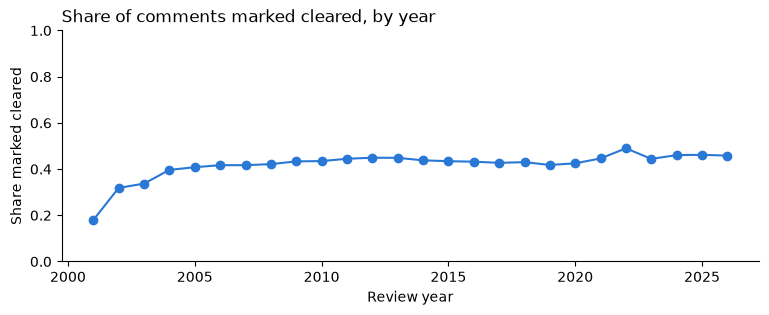

,comments,share_cleared
STATUS,,
Assigned,409,0.00
Assignment Pending,462077,0.01
Cancelled,1587124,0.03
Closed,14407079,0.43
Completed,32016,0.51
Started,333,0.35


In [11]:
cleared = (issues["IS_CLEARED_IND"] == "Y").rename("cleared")
print("Flag is 'Y' exactly when CLEARED_DT is filled:", bool((cleared == issues["CLEARED_DT"].notna()).all()))
print(f"Share of all comments marked cleared: {cleared.mean():.0%}")

by_year = cleared.groupby(issues["year"]).agg(["size", "mean"])
by_year = by_year[by_year["size"] >= 1000]   # ignore years with very few comments
by_status = cleared.groupby(issues["STATUS"]).agg(comments="size", share_cleared="mean").round(2)

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(by_year.index.astype(int), by_year["mean"], marker="o", color=BLUE)
ax.set_ylim(0, 1)
ax.set_xlabel("Review year")
ax.set_ylabel("Share marked cleared")
ax.set_title("Share of comments marked cleared, by year", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()
by_status

**What this means.** The "cleared" flag is **not a reliable record of resolution**, and it does not get better in recent years.
- It is "Y" exactly when `CLEARED_DT` is filled, so the two columns carry the same information.
- Only 38% of all comments are marked cleared. The share is about 40% to 49% in every year from 2004 on (lower in 2001 to 2003, about 18% to 34%).
- Even in reviews with status Closed, only 43% of comments are marked cleared, and in Cancelled reviews 3%. So more than half of the comments in finished reviews were never marked cleared, which means "N" mostly means "nobody clicked it", not "still open". We should not use this flag as an outcome.

## 2. Permit type from `SCOPE`

`SCOPE` is the project description typed in by staff. It repeats on every comment of a project, so we work with one row per project (`PROJ_ID`) and merge the result back. We first look at a random sample and at the most common starting words.

In [12]:
scopes = issues.drop_duplicates("PROJ_ID")[["PROJ_ID", "SCOPE"]].reset_index(drop=True)
print(f"{len(scopes):,} projects, {scopes['SCOPE'].isna().sum()} with no SCOPE\n")

print("Random sample of SCOPE values:")
for s in scopes["SCOPE"].dropna().sample(20, random_state=SEED):
    print(" -", " ".join(s.split())[:115])

216,375 projects, 372 with no SCOPE

Random sample of SCOPE values:
 - Channel maintenance project to manual cutting and removal of vegetation located in a concrete channel in a buisness
 - LA JOLLA: Combination building permit to an existing single family residence. Work to include a new yoga and exerci
 - UNIVERSITY Building permit for new storage racks to replace shelving at an existing mall retail store. CR-1-1 PDP 4
 - MISSION VALLEY - Building, electrical and mechanical permits for improvements includiing HVAC equuipment, and new e
 - Construction change to pts 356164, approval 1246607. Construction change to trusses. Change in pitch and roof heigh
 - PENINSULA. Building, electrical, mechanical, and plumbing permits for remodel to extg office building. Work to incl
 - **SCOPE CHANGE**DOWNTOWN Building, Electrical, Mechanical, and Plumbing Permits for a tenant improvement of a new r
 - CENTER CITY J.O.# 424405 Grading Permit for Shoring for 175 Residential Condominiums. Reference 

In [13]:
first_words = scopes["SCOPE"].dropna().str.split().str[:2].str.join(" ").str.upper()
print("Most common first two words:")
first_words.value_counts().head(12).to_frame("projects")

Most common first two words:


,projects
SCOPE,
CONSTRUCTION CHANGE,12771
LA JOLLA,4755
GREATER NORTH,4212
DEFERRED FIRE,4170
MIRA MESA,2865
ELECTRICAL PERMIT,2700
SOUTHEASTERN SAN,2683
LA JOLLA:,2142
BLACK MOUNTAIN,2057


The formats are all over the place. Some start with a project number and permit codes (`41-0458 CDP/VAR (Process 3) ...`), but most start with a community name (`MIRA MESA: Combination Building Permit for ...`), and others have no permit words at all (`Interior tenant improvement ...`). How much of this did the earlier regex catch?

In [14]:
old_pattern = r"^\s*[\d-]+\s+([A-Z/&\s]+?)\s*\(Process"
old_hits = scopes["SCOPE"].str.extract(old_pattern)[0].notna().sum()
print(f"Earlier regex matches {old_hits} of {len(scopes):,} projects ({old_hits / len(scopes):.3%})")

Earlier regex matches 5 of 216,375 projects (0.002%)


**New approach: ordered keyword rules.** Instead of one pattern anchored to the start, we look for permit-type words in the first 200 characters (the type is stated up front; later text often mentions other permits in passing). Rules are tried in priority order and the first match wins:

1. Explicit words first (`construction change`, `deferred`), then the permit names written out (`Combination Building Permit`, `Building Permit`), then other types.
2. **Discretionary permit codes** (CDP, SDP, CUP, ...) count only when a **Process level** is stated, because that marks a real discretionary project. Otherwise a code is usually just a reference inside a building permit (`... Zone: RS-1-4 / SDP#40-0508`). A code is also used when nothing else matched.
3. Anything still unmatched is labelled `Unknown` (never dropped).

The process level (`Process 1` to `Process 5`, written as digits or words) is read separately. The rules were tuned by repeatedly looking at what stayed `Unknown` and at wrong matches (for example the word "row" in "row homes").

In [15]:
HEAD = 200  # characters of SCOPE to search
text = scopes["SCOPE"].fillna("").str.replace(r"\s+", " ", regex=True).str.strip().str[:HEAD]

# Process level: "Process 3", "PROCESS TWO", "Process No. 4"
words = {"one": "1", "two": "2", "three": "3", "four": "4", "five": "5"}
scopes["process_level"] = (
    text.str.extract(r"(?i)\bprocess\s*(?:no\.?\s*)?(1|2|3|4|5|one|two|three|four|five)\b")[0]
    .str.lower().replace(words)
)

# Discretionary permit codes. Spelled-out names become codes, then we take the first code in the text.
spelled_out = {"coastal development permit": "CDP", "site development permit": "SDP",
               "neighborhood development permit": "NDP", "neighborhood use permit": "NUP",
               "conditional use permit": "CUP", "planned development permit": "PDP", "variance": "VAR"}
code_names = {"CDP": "Coastal Development Permit (CDP)", "SDP": "Site Development Permit (SDP)",
              "NDP": "Neighborhood Development Permit (NDP)", "NUP": "Neighborhood Use Permit (NUP)",
              "CUP": "Conditional Use Permit (CUP)", "PDP": "Planned Development Permit (PDP)",
              "VAR": "Variance (VAR)"}
with_codes = text
for name, abbreviation in spelled_out.items():
    with_codes = with_codes.str.replace(name, abbreviation, case=False, regex=False)
permit_code = with_codes.str.extract(r"\b(CDP|SDP|NDP|NUP|CUP|PDP|VAR)\b")[0].map(code_names)  # codes must be uppercase

# Keyword rules, highest priority first. (?i) = ignore case; (?-i:...) = case-sensitive piece.
RULES = [
    ("Construction Change", r"(?i)construction chang|const\.? chg|^CC\b|\bdelta\b"),
    ("Deferred Submittal", r"(?i)deferred"),
    ("Combination Building Permit", r"(?i)combination|\bcombo\b"),
    ("Building Permit", r"(?i)\b(?:building|bldg)\b.{0,60}\bpermits?\b"),
    ("Map / Rezone / Plan Amendment", r"(?i)(?-i:\bTPM?\b)|tentative map|parcel map|map waiver|lot line|lot consolidation|dedication|final map|rezone|re-zone|community plan amend|\bCPA\b"),
    ("Right-of-Way / Street Work", r"(?i)right[- ]of[- ]way|(?-i:\bR-?O-?W\b|\bPROW\b)"),
    ("Zone History Letter", r"(?i)zone history|\bZHL\b"),
    ("Zoning Affidavit", r"(?i)zoning affidavit"),
    ("Public Project / Improvements", r"(?i)public project|public improvement|\bPPA\b|\bWBS\b|\bCIP\b|improvement plans"),
    ("Easement / Street Vacation", r"(?i)easement|vacation"),
    ("Right-of-Way / Street Work", r"(?i)\btrench\w*|\bexcavat\w*|\bdig\b|street asphalt"),
    ("Demolition", r"(?i)demolition|\bdemo\b"),
    ("Grading", r"(?i)\bgrading\b|as[- ]graded"),
    ("Tenant Improvement", r"(?i)tenant impr|\bT\.?\s?I\.?\b"),
    ("Sign", r"(?i)\bsigns?\b|signage"),
    ("Solar / Photovoltaic", r"(?i)solar|photovoltaic|\bPV\b"),
    ("Pool / Spa", r"(?i)\bpool\b|\bspa\b"),
    ("Companion / Junior Unit", r"(?i)companion unit|junior unit|\bJADU\b|\bADU\b"),
    ("Fire Systems", r"(?i)fire (?:alarm|sprinkler|service|suppression|permit)|sprinkler|suppression|hydrant"),
    ("Wireless / Telecom", r"(?i)wireless|\bWCF\b|telecom|cell site|antenna"),
    ("Electrical / Plumbing / Mechanical", r"(?i)\b(?:electrical|plumbing|mechanical|elect|mech)\b.{0,15}\b(?:permits?|only)\b"),
    ("Preliminary / Multi-Discipline Review", r"(?i)pre-?lim\w*(?:\s+planning)?(?:\s+review)?|pre-?application|multi[- ]?disc\w*|single disc\w*|screen check|\bSCR\b|substantial conformance"),
    ("Other building work", r"(?i)\b(?:addition|remodel\w*|residence|dwelling|single family|foundation|repair|conversion|improvements?|sfr|sfd|sfu|sdu|duplex|garage|patio|deck|retaining wall|ret walls?|fence|roof|windows?|interior|convert\w*|construct\w*|install\w*|alteration|upgrade|master plan|new)\b"),
]

scopes["permit_type"] = "Unknown"
for label, pattern in reversed(RULES):          # lowest priority first, so higher-priority rules overwrite it
    scopes.loc[text.str.contains(pattern, regex=True), "permit_type"] = label

# A discretionary code wins when a Process level is stated, or when nothing else matched
explicit = scopes["permit_type"].isin(["Construction Change", "Deferred Submittal"])
use_code = permit_code.notna() & ~explicit & (scopes["process_level"].notna() | (scopes["permit_type"] == "Unknown"))
scopes.loc[use_code, "permit_type"] = permit_code[use_code]

issues = issues.merge(scopes[["PROJ_ID", "permit_type", "process_level"]], on="PROJ_ID", how="left")

How well did it work? Share of comments and projects left as `Unknown`, the most common permit types, and examples of what failed.

Unknown: 1.3% of comments, 2.8% of projects
Process level found on 14.0% of comments

                                       comments   pct
permit_type                                          
Building Permit                         5013640  30.4
Combination Building Permit             4397354  26.7
Right-of-Way / Street Work               962471   5.8
Map / Rezone / Plan Amendment            685155   4.2
Other building work                      656958   4.0
Coastal Development Permit (CDP)         605615   3.7
Site Development Permit (SDP)            563678   3.4
Construction Change                      523652   3.2
Preliminary / Multi-Discipline Review    479761   2.9
Planned Development Permit (PDP)         327059   2.0 



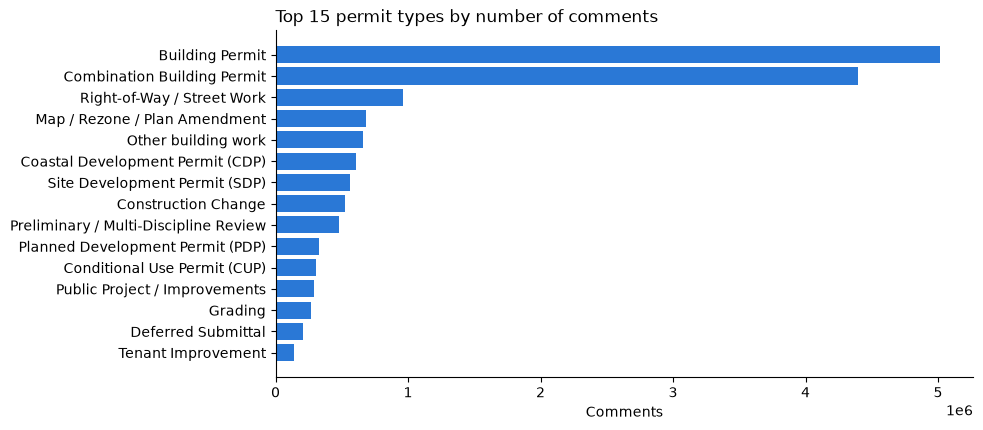

Examples left Unknown:
 - SESD,BLDGNew Single Story RestaurantSF-5000 96-0338 STEEP HILLSIDES Owner: BMW Management Cen. tract 33.00.
 - $$DEL MAR MESA SP, JO# 424165, Street name change from Del Mar Nation to The Grand Del Mar Way. Zone = AR-1-1,
 - Electrical, Partitions, and mechanical for an existing commerical office. No change in use. Mission Valley Com
 - PARTITION, ELEC. FOR EXISTING RETAIL SPACE ******CT-2-3***
 - SABRE SPRINGS; PARTITION WALLS, CEILING, ELELCTRICAL, MECHANICAL, PLUMBING (17 FU'S) FOR OFFICE/SHOWROOM.*****
 - Zoning History Letter @ 12670 & 12680 High Bluff Drive NCW Permit No. 86-0231
 - NEPA Review for social services and other (technical assistance, training) including general program administr
 - CENTRE CITY ONE non illuminated projecting sing for "Andaz" hotel Designated Historic # 701, CCPD-ER
 - DEL MAR MESA, Multiple Retaing walls - note only walls highlighted are under this permit Zone = AR-1-1, Coasta
 - Request for Zoning History Letter for 7901 Har

In [16]:
by_type = issues["permit_type"].value_counts().to_frame("comments").assign(pct=lambda d: (d["comments"] / len(issues) * 100).round(1))
print(f"Unknown: {by_type.loc['Unknown', 'pct']}% of comments, {(scopes['permit_type'] == 'Unknown').mean():.1%} of projects")
print(f"Process level found on {issues['process_level'].notna().mean():.1%} of comments\n")

top15 = by_type.drop("Unknown").head(15)
print(top15.head(10).to_string(), "\n")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top15.index[::-1], top15["comments"][::-1], color=BLUE)
ax.set_xlabel("Comments")
ax.set_title("Top 15 permit types by number of comments", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

print("Examples left Unknown:")
for s in scopes.loc[scopes["permit_type"] == "Unknown", "SCOPE"].dropna().sample(12, random_state=SEED):
    print(" -", " ".join(s.split())[:110])

In [17]:
issues.drop_duplicates("PROJ_ID")["process_level"].value_counts(dropna=False).to_frame("projects").T

process_level,NaN,3,2,4,1,5
projects,207063,3674,2454,1602,836,746


**What this means.**
- The earlier regex matches only 5 of 216,375 projects: it only fits the old `41-0458 CDP/VAR (Process 3)` style.
- The new rules leave **1.3% of comments** (2.8% of projects) as `Unknown`. The leftovers are mostly one-offs, such as alternate-materials requests, certificates of compliance, test projects, or scopes with no permit words at all.
- **Building Permit** and **Combination Building Permit** together make up more than half of all comments (30% and 27%). Right-of-way work, maps/rezones, and the discretionary permits (CDP, SDP, PDP, CUP) follow.
- Process levels appear on about 14% of comments (about 9,300 projects, mostly Process 3). They go with discretionary projects, which are reviewed in a more formal way.
- **Limits:** the type is a best guess from free text, each project gets exactly one type, `Other building work` (about 4% of comments) is a catch-all, and "Building" vs. "Combination" follows the words staff typed, not an official permit code.

**Do older comments look different?** The data starts in 2001. Before using all of it, we compare the mix of permit types across periods (share of comments, %). Rows with no year are left out of this table.

In [18]:
era = pd.cut(issues["year"].astype(float), [2000, 2009, 2013, 2021, 2100], labels=["2001-09", "2010-13", "2014-21", "2022+"])
top_types = issues["permit_type"].value_counts().index[:8]
type_group = issues["permit_type"].where(issues["permit_type"].isin(top_types), "all others")
pd.crosstab(era, type_group, normalize="index").mul(100).round(0).astype(int)

permit_type,Building Permit,Coastal Development Permit (CDP),Combination Building Permit,Construction Change,Map / Rezone / Plan Amendment,Other building work,Right-of-Way / Street Work,Site Development Permit (SDP),all others
year,,,,,,,,,
2001-09,26,5,24,1,7,10,2,5,20
2010-13,38,3,29,2,3,3,3,3,16
2014-21,34,3,31,4,3,2,8,2,14
2022+,12,7,14,21,2,1,9,3,31


**What this means.** Permit mix is similar for 2010 to 2013 and 2014 to 2021, but 2001 to 2009 looks different: 10% of comments fall in the catch-all `Other building work` (1% to 3% later), map/rezone is 7% (2% to 3% later), and right-of-way and construction changes are rare. Part of this is probably older scopes being written differently, so they are harder to classify. 2022 and later is thin and dominated by construction changes (21%). We therefore keep **2010 onward**. This is a judgment call: change `MIN_YEAR` at the top to test it.

In [19]:
recent = issues.loc[issues["year"] >= MIN_YEAR, ["DISCIPLINE", "permit_type", "year", "ISSUE_TEXT"]].copy()
print(f"Keeping review years >= {MIN_YEAR}: {len(recent):,} of {len(issues):,} comments ({len(recent) / len(issues):.0%})")
print(f"Dropped: {(issues['year'] < MIN_YEAR).sum():,} older comments and {issues['year'].isna().sum():,} with no year")
print("Statuses of the no-year rows:", issues.loc[issues["year"].isna(), "STATUS"].value_counts().to_dict())
del issues   # lighter run: only these four columns are needed from here on
import gc; gc.collect()


Keeping review years >= 2010: 10,965,854 of 16,489,038 comments (67%)
Dropped: 3,673,077 older comments and 1,850,107 with no year
Statuses of the no-year rows: {'Cancelled': 1388500, 'Assignment Pending': 461607}


2425

**What this means.** We keep two thirds of the comments (10,965,854). The 1,850,107 comments with no year come from cancelled (1,388,500) and never-assigned (461,607) reviews. They cannot be placed in time, so they are left out here. That loses some comments from cancelled reviews, which is a small bias to keep in mind.

## 3. Method 1: exact and near-exact repeats

To find comments that are "the same" even when small details differ, we normalize the text: lowercase, turn sheet or page references into the word `sheet`, remove all numbers, remove punctuation, and collapse extra spaces. For example, `See sheet A-2.1 and A-3 for the detail` becomes `see sheet for the detail`. Then we count how often each normalized comment occurs.

We also keep a cleaned copy of the original text (phone numbers, emails, and names written next to them masked) to show as readable examples.

In [20]:
sheet_ref = r"\b(?:sheets?|pages?|pgs?)\b[\s.#:]*(?:no\.?)?\s*[a-z]{0,2}[-.\s]?\d[\w.\-/]*(?:\s*(?:,|and|&|thru|through)\s*[a-z]{0,2}[-.\s]?\d[\w.\-/]*)*"
# phone numbers and emails, plus a capitalized name written right before them ("Call Ron (619) ...")
contact = r"(?:\b[A-Z][a-z]+(?:\s[A-Z][a-z]+)?\s+(?:at\s+)?)?(?:\(?\b\d{3}\)?[-.\s]\d{3}[-.\s]\d{4}\b|\b[\w.+-]+@[\w-]+\.[\w.]+\b)"


def normalize(text):
    t = text.str.lower()
    t = t.str.replace(sheet_ref, "sheet", regex=True)   # "sheets 3, 4 & 5" -> "sheet"
    t = t.str.replace(r"\d+", " ", regex=True)          # numbers
    t = t.str.replace(r"[^a-z\s]", " ", regex=True)     # punctuation and symbols
    return t.str.replace(r"\s+", " ", regex=True).str.strip()


# Lighter run: normalize in chunks of 1M rows so the temporary copies stay small
recent["norm"] = pd.concat([normalize(recent["ISSUE_TEXT"].iloc[i:i + 1_000_000]) for i in range(0, len(recent), 1_000_000)])

blank = recent["norm"] == ""
print(f"Dropping {blank.sum()} comments that were only numbers or symbols")
recent = recent[~blank].copy()

# One readable example per distinct normalized comment (the first one seen), with phone numbers and emails masked.
# Built once here; after that the raw text is dropped to save memory.
first_text = recent.drop_duplicates("norm").set_index("norm")["ISSUE_TEXT"]
EXAMPLE = first_text.str.replace(r"\s+", " ", regex=True).str.replace(contact, "[contact]", regex=True).str.strip()
n_distinct_before = recent["ISSUE_TEXT"].nunique()
recent = recent.drop(columns="ISSUE_TEXT")
del first_text; gc.collect()
print(f"{len(recent):,} comments, {recent['norm'].nunique():,} distinct after normalizing, {n_distinct_before:,} distinct before")


Dropping 379 comments that were only numbers or symbols


10,965,475 comments, 2,568,900 distinct after normalizing, 2,855,506 distinct before


In [21]:
def unique_comments(frame):
    """One row per distinct normalized comment, most common first: how often it occurs and one readable example."""
    out = frame["norm"].value_counts().rename_axis("norm").reset_index(name="count")
    out = out.sort_values(["count", "norm"], ascending=[False, True], ignore_index=True)
    out["example"] = out["norm"].map(EXAMPLE)
    out["pct"] = (out["count"] / len(frame) * 100).round(2)
    return out


def top_comments(frame, n=10):
    out = unique_comments(frame).sort_values("count", ascending=False).head(n)[["count", "pct", "example"]]
    out["example"] = out["example"].str[:110]   # keep the tables narrow
    return out


print("Top 20 most common comments overall")
top_comments(recent, 20)

Top 20 most common comments overall


,count,pct,example
0,65101,0.59,Please indicate here if any changes have been made to the plans that are not a result of corrections from ...
1,54046,0.49,This list does not necessarily include all errors and omissions. Plans require correction as indicated by ...
2,40351,0.37,It is the responsibility of architect or engineer of record to ensure that all requirements of the latest ...
3,33493,0.31,"All Issue Boxes without check marks, requirements still need to be corrected or addressed. Please Indicate..."
4,27995,0.26,"To facilitate rechecking, provide an itemized written response to the issues noted in this plan review she..."
5,26222,0.24,"For useful and detailed information concerning the plan review, permit process, and number of plans and do..."
6,24829,0.23,"Please come back for a ""Walk-in"" over the counter re- check when all corrections have been provided, note ..."
7,23955,0.22,"Please be advised, supplemental plan review fees may be charged where insufficient progress is made in res..."
8,22953,0.21,This plan can be rechecked over the counter (OTC) by any electrical plan reviewer.
9,21467,0.20,It is the responsibility of the architect or engineer of record to assure that all requirements of the lat...


**What this means.** The most common comments are **not about any one project**. They are standard text that reviewers paste into reviews:
- form instructions ("Please indicate here if any changes have been made to the plans..." appears 65,101 times; "This list does not necessarily include all errors and omissions..." 54,046 times),
- how to recheck or resubmit (itemized written response, walk-in recheck, recheck by appointment, "can be rechecked over the counter by any electrical plan reviewer"),
- notices (the architect or engineer of record is responsible for code compliance, supplemental review fees, historic-resource review steps, links to DSD web pages).

All 20 are of this kind. Each one still covers under 1% of comments, because the same text exists in many slightly different versions.

The same view inside each of the six biggest disciplines: what does each group of reviewers repeat most?

In [22]:
for discipline in recent["DISCIPLINE"].value_counts().index[:6]:
    sub = recent[recent["DISCIPLINE"] == discipline]
    print(f"\n=== {discipline} ({len(sub):,} comments)")
    print(top_comments(sub, 10).to_string(index=False, header=["count", "pct", "example"]))


=== BDR-Structural (3,753,066 comments)


count  pct                                                                                                        example
27690 0.74 To facilitate rechecking, provide an itemized written response to the issues noted in this plan review sheet. 
26042 0.69 For useful and detailed information concerning the plan review, permit process, and number of plans and docume
25281 0.67 Please indicate here if any changes have been made to the plans that are not a result of corrections from this
23800 0.63 Please be advised, supplemental plan review fees may be charged where insufficient progress is made in respond
21302 0.57 It is the responsibility of the architect or engineer of record to assure that all requirements of the latest 
20958 0.56 Projects initially reviewed over-the-counter on the 3rd floor can be rechecked with any structural reviewer at
18927 0.50 Recheck of plans will be performed by appointment. For a recheck appointment, please call [contact]. Please ha
18223 0.49 Plans require

count  pct                                                                                                        example
33084 2.65 All Issue Boxes without check marks, requirements still need to be corrected or addressed. Please Indicate the
22580 1.81 Please come back for a "Walk-in" over the counter re- check when all corrections have been provided, note the 
 9387 0.75 Provide name, address, and phone number of the Financially Responsible Party for the Water & Sewer fees associ
 9001 0.72            This is not a complete plan check more comments may follow when additional information is provided.
 7049 0.56                              Output Capacity- Show the output capacity of the heating unit on the floor plans.
 6949 0.56 Note on the plan: " An electronically signed and registered Installation Certificate(s) (CF-6R) posted by the 
 6796 0.54 The backflow assembly for a domestic and/or irrigation meter shall be located immediately to the rear of meter
 6499 0.52             N

count  pct                                                                                                        example
 4833 0.56 To facilitate rechecking, provide an itemized written response to the issues noted in this plan review sheet. 
 3727 0.43                                    Please see plans/documents/reports for additional corrections and comments.
 2948 0.34   FYI: All review disciplines must sign off prior to obtaining LDR-Drainage and Grades' approval and sign off.
 2824 0.32                                                 Please refer to the redlined plan set for additional comments.
 2752 0.32 On your following review, please provide a copy of the redline/mark-up plans and/or marked up documents/report
 2659 0.31 Please address the following comments/review issues as directed. To facilitate rechecking, provide a separate 
 2278 0.26                                                Please see plans/documents for additional corrections/comments.
 1973 0.23              

count  pct                                                                                                        example
39832 5.09 This list does not necessarily include all errors and omissions. Plans require correction as indicated by comm
39746 5.08 It is the responsibility of architect or engineer of record to ensure that all requirements of the latest adop
36943 4.72 Please indicate here if any changes have been made to the plans that are not a result of corrections from this
19424 2.48 Provide an Itemized Written Response to the issues noted in this plan review sheet. The Written Response shall
16478 2.11 The mechanical and plumbing plans must be stamped and signed by the California licensed professional who is re
14989 1.92                             This plan can be rechecked over the counter (OTC) by any mechanical plan reviewer.
 8302 1.06 Obtain Health Department approval (5500 Overland Ave., Suite #110 & 210, San Diego, CA 92123). Contact the [co
 6113 0.78 Add note: "Bu

count  pct                                                                                                        example
 3569 0.71 Please provide a table with the following Earthwork Quantities: Cut Quantities: ________ cyd Fill Quantities: 
 3310 0.66 Please add the following note on the Site Plans: The project proposes to export ____ cubic yards of material f
 2376 0.47 The Engineering Building Review Section has reviewed the subject development and has the following comments th
 2216 0.44 Please provide a table with the following information: a. Total Disturbance Area: _________ b. Existing amount
 2135 0.43 Add the following note to the Site Plan: All storm water runoff from proposed and/or replaced impervious areas
 2016 0.40 FYI: The plans and documents have been reviewed, redlined, and were routed to plan pickup. Please pick up the 
 1750 0.35 To facilitate rechecking, provide an itemized written response to the issues noted in this plan review sheet. 
 1623 0.32              

count  pct                                                                                                        example
10938 3.23                                               Additional comments may follow when new information is provided.
 2667 0.79 Three sets of approved plans are required to obtain Building Permits for construction. The first two sets of p
 2660 0.79            This is not a complete plan check more comments may follow when additional information is provided.
 2249 0.66 Please come back for a "Walk-in" over the counter re- check when all corrections have been provided, note the 
 1898 0.56 The third set of plans does not require the approval stamps or construction details. It is forwarded to the Co
 1790 0.53  Plans must be resubmitted. Please answer all issues and provide a copy of the responses with the resubmittal.
 1631 0.48 one set of the corrected plans and the original Plans require corrections as indicated by the clear issue box 
 1531 0.45 Zoning regula

**What this means.** Each discipline has its own set of standard comments, and they come in two flavors.
- **Process notices.** In BDR-Structural and BDR-Mechanical the top comments are recheck instructions and responsibility notices. In Mechanical, the top three alone are about 15% of the discipline's comments (5.1%, 5.1%, 4.7%).
- **Plan content that is often missing.** In IAS-Combined Review the repeated requests are specific: who pays the water and sewer fees, where the backflow assembly goes, make/model/capacity of the water heater, output of the heating unit, clearance around toilets. In LDR-Eng Building Review: earthwork quantities and impervious-area tables, and a standard storm-water note. These are natural candidates for an applicant checklist, since applicants are being asked for the same things again and again.
- LDR-Drainage & Grades has more variety; its top comments are about redlines and written responses.

And inside the four biggest permit types (leaving out `Unknown`).

In [23]:
for permit in recent["permit_type"].value_counts().drop("Unknown").index[:4]:
    sub = recent[recent["permit_type"] == permit]
    print(f"\n=== {permit} ({len(sub):,} comments)")
    print(top_comments(sub, 5).to_string(index=False, header=["count", "pct", "example"]))


=== Building Permit (3,751,731 comments)


count  pct                                                                                                        example
45319 1.21 Please indicate here if any changes have been made to the plans that are not a result of corrections from this
39017 1.04 This list does not necessarily include all errors and omissions. Plans require correction as indicated by comm
33392 0.89 It is the responsibility of architect or engineer of record to ensure that all requirements of the latest adop
16778 0.45 Projects initially reviewed over-the-counter on the 3rd floor can be rechecked with any structural reviewer at
15698 0.42 Provide an Itemized Written Response to the issues noted in this plan review sheet. The Written Response shall



=== Combination Building Permit (3,263,855 comments)


count  pct                                                                                                        example
24765 0.76 All Issue Boxes without check marks, requirements still need to be corrected or addressed. Please Indicate the
16986 0.52 Please come back for a "Walk-in" over the counter re- check when all corrections have been provided, note the 
14617 0.45 If City staff determines that a potentially significant historical resource exists on the site, all modificati
14615 0.45 (...continued) If the proposed project is not consistent with the Standards, the applicant may redesign the pr
14601 0.45 If City staff determines after review of these documents that no potentially significant historical resource e

=== Right-of-Way / Street Work (781,231 comments)


count  pct                                                                                                        example
 2877 0.37                                                 Please refer to the redlined plan set for additional comments.
 2421 0.31 Please address the following comments/review issues as directed. To facilitate rechecking, provide a separate 
 2268 0.29                                                                    Please see redline for additional comments.
 2186 0.28 To facilitate rechecking, provide an itemized written response to the issues noted in this plan review sheet. 
 1680 0.22                                                                                            New Issue (4706261)

=== Construction Change (468,196 comments)


count  pct                                                                                                        example
 3681 0.79 Please indicate here if any changes have been made to the plans that are not a result of corrections from this
 3659 0.78 This list does not necessarily include all errors and omissions. Plans require correction as indicated by comm
 2761 0.59 It is the responsibility of architect or engineer of record to ensure that all requirements of the latest adop
 2480 0.53 Provide an Itemized Written Response to the issues noted in this plan review sheet. The Written Response shall
 2449 0.52 Recheck of plans will be performed by appointment. For a recheck appointment, please call [contact]. Please ha


**What this means.** Building Permit and Construction Change reviews share the same standard text (the "changes made?" form, "list does not include all errors", the architect-of-record notice). Combination Building Permits lead with the "issue boxes" and walk-in recheck text and also carry the historic-resource notices. Right-of-Way / Street Work is different: its top comments are short and free-form ("refer to the redlined plan set") and each covers only about 0.3% of comments (at most 0.37%), so this type has much less boilerplate.

**How much of everything is boilerplate?** We rank the distinct normalized comments by how often they occur and ask what share of all comments the top N cover.

Comments whose normalized text appears more than once: 95.8%


Comments whose normalized text appears 10+ times:      49.7%
Distinct comments needed to cover half of all comments: 52,085 of 2,568,900



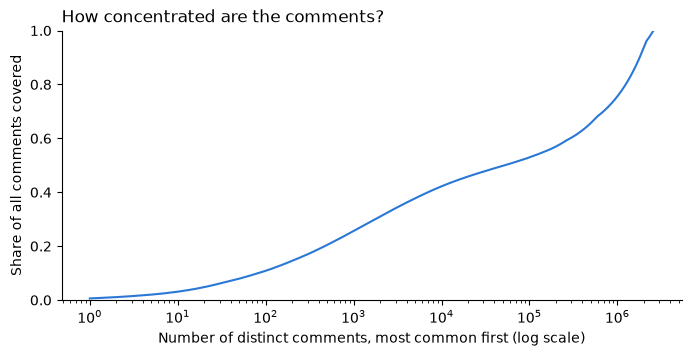

,top_N_distinct_comments,share_of_all_comments
0,10,3.1%
1,100,10.9%
2,1000,25.6%
3,10000,42.2%


In [24]:
counts = recent["norm"].value_counts()
covered = counts.cumsum() / len(recent)

coverage = pd.DataFrame({"top_N_distinct_comments": [10, 100, 1000, 10000]})
coverage["share_of_all_comments"] = [f"{covered.iloc[n - 1]:.1%}" for n in coverage["top_N_distinct_comments"]]
print(f"Comments whose normalized text appears more than once: {(recent['norm'].map(counts) > 1).mean():.1%}")
print(f"Comments whose normalized text appears 10+ times:      {(recent['norm'].map(counts) >= 10).mean():.1%}")
print(f"Distinct comments needed to cover half of all comments: {(covered < 0.5).sum() + 1:,} of {len(counts):,}\n")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(np.arange(1, len(covered) + 1), covered.values, color=BLUE)
ax.set_xscale("log")
ax.set_xlabel("Number of distinct comments, most common first (log scale)")
ax.set_ylabel("Share of all comments covered")
ax.set_title("How concentrated are the comments?", loc="left")
ax.set_ylim(0, 1)
ax.spines[["top", "right"]].set_visible(False)
plt.show()
coverage

**What this means.**
- **96%** of comments have a normalized text that appears more than once, and **50%** appear 10 or more times. Only 4% are one-offs.
- No handful of comments dominates: the top 10 cover only 3.1%, the top 100 cover 11%, the top 1,000 cover 26%, and the top 10,000 cover 42%.
- Half of all comments come from just 52,085 of the 2,568,900 distinct comments (about 2%).

So repetition is widespread but spread over many variants. Our normalization only fixes case, numbers, and punctuation. Rewordings and typos still count as different comments, so real repetition is higher than this, which is why we cluster next.

**Compared with the first 10 files** (3.3 million comments from 2010 on) and the first 2 files (about 660,000): the share that repeats rose from 53% (2 files) to 70% (10 files) to 96% (33 files), the share appearing 10+ times from 38% to 45% to 50%, and the share of distinct wordings needed to cover half of all comments fell from about 8% to 3% to 2%. More data finds more repeats of the same text, because each wording has more chances to recur. The top-10 / top-100 / top-1,000 / top-10,000 coverage (3.1% / 11% / 26% / 42%) did not move at all between 10 and 33 files.

## 4. Method 2: TF-IDF and KMeans clustering

Exact matching misses comments that say the same thing in different words. TF-IDF turns each comment into numbers that capture which words it uses (down-weighting very common words), and KMeans then groups comments with similar wording.

To keep it fast, we cluster the **distinct normalized comments** (2.6 million instead of 11 million rows) and **weight each one by how many times it occurs**, so a comment repeated 3,000 times counts 3,000 times. The vocabulary is the 5,000 most useful words and word pairs (stop words like "the" are ignored; a term must appear in at least 5 distinct comments).

**Lighter run for 33 files.** Clustering all 2.6 million distinct comments at once needs too much memory, so the vocabulary and the clusters are learned from the **600,000 most common distinct comments** (68% of all comments). Every other, rarer wording is then assigned to its nearest cluster centre. The displayed examples come from the 600,000 clustered directly.

In [25]:
FIT_MAX = 600_000   # lighter run: learn the vocabulary and clusters from the 600k most common distinct comments


def fit_tfidf(uniq):
    """TF-IDF on the FIT_MAX most common distinct comments (`uniq` must be sorted, most common first)."""
    vec = TfidfVectorizer(stop_words="english", min_df=5, max_features=5000, ngram_range=(1, 2))
    return vec, vec.fit_transform(uniq["norm"].iloc[:FIT_MAX])


def fit_kmeans(vec, X, uniq, k, n_init=3):
    """KMeans (weighted by comment counts) on the rows of X. Rarer comments beyond FIT_MAX are then assigned to the
    nearest cluster centre in chunks, so every comment gets a cluster. Clusters are renumbered so 0 is the biggest."""
    m, counts = X.shape[0], uniq["count"].values
    km = KMeans(n_clusters=k, n_init=n_init, random_state=SEED).fit(X, sample_weight=counts[:m])
    centers = km.cluster_centers_
    labels = np.empty(len(uniq), dtype=int)
    labels[:m] = km.labels_
    bias = 0.5 * (centers ** 2).sum(axis=1)     # nearest centre = largest (x . c - |c|^2 / 2) for unit-length x
    for start in range(m, len(uniq), 200_000):
        chunk = vec.transform(uniq["norm"].iloc[start:start + 200_000])
        labels[start:start + 200_000] = np.asarray(chunk @ centers.T - bias).argmax(axis=1)
    size = pd.Series(counts).groupby(labels).sum().sort_values(ascending=False)
    new_id = {old: new for new, old in enumerate(size.index)}
    return pd.Series(labels).map(new_id).values, centers[size.index]


def show_clusters(uniq, vec, X, labels, centers, n_examples=3):
    """Print size, top terms, and the comments closest to each cluster centre. Returns a summary table."""
    terms = np.array(vec.get_feature_names_out())
    rows = []
    for c in range(len(centers)):
        idx = np.where(labels == c)[0]
        top_terms = ", ".join(terms[np.argsort(-centers[c])[:7]])
        share = uniq["count"].values[idx].sum() / uniq["count"].sum()
        rows.append({"cluster": c, "pct_of_comments": round(share * 100, 1), "distinct_comments": len(idx), "top_terms": top_terms})
        print(f"\n[{c}] {share:.1%} of comments, {len(idx):,} distinct | {top_terms}")
        idx_fit = idx[idx < X.shape[0]]          # examples come from the rows that were clustered directly
        for i in idx_fit[np.argsort(-(X[idx_fit] @ centers[c]))[:n_examples]]:
            print("     -", uniq["example"][i][:140])
    return pd.DataFrame(rows).set_index("cluster")


uniq = unique_comments(recent)
vec, X = fit_tfidf(uniq)
counts = uniq["count"].values
print(f"Distinct comments: {len(uniq):,} | clustered directly: {X.shape[0]:,} | vocabulary size: {X.shape[1]:,}")
print(f"The clustered ones cover {counts[:X.shape[0]].sum() / counts.sum():.1%} of all comments; the rest are assigned to the nearest cluster.")

Distinct comments: 2,568,900 | clustered directly: 600,000 | vocabulary size: 5,000
The clustered ones cover 68.3% of all comments; the rest are assigned to the nearest cluster.


**Choosing k (the number of clusters).** We try a few values and look at the silhouette score on a sample (it measures how well separated the clusters are, from -1 to 1) and at how lopsided the clusters are.

In [26]:
trials = []
m = X.shape[0]
for k in [10, 20, 30, 40]:
    labels_k, _ = fit_kmeans(vec, X, uniq, k, n_init=1)
    share = pd.Series(counts).groupby(labels_k).sum() / counts.sum()
    trials.append({"k": k,
                   "silhouette": round(silhouette_score(X, labels_k[:m], sample_size=5000, random_state=SEED), 3),
                   "largest_cluster_share": round(share.max(), 2),
                   "clusters_under_1pct": int((share < 0.01).sum())})
pd.DataFrame(trials).set_index("k")


,silhouette,largest_cluster_share,clusters_under_1pct
k,,,
10,-0.000,0.55,0
20,-0.005,0.44,6
30,-0.002,0.38,11
40,-0.004,0.39,19


**What this means.** Silhouette is about 0 for every k (-0.005 to 0.000). That is normal for short, sparse text with one huge generic group, and it means the clusters are **not sharply separated**, so it cannot pick k for us. More clusters shrink the biggest one (55% at k=10, 44% at k=20, 38% at k=30, 39% at k=40) but create many tiny ones (0, 6, 11, and 19 clusters under 1%). We use **k = 20**: themes are readable and the clusters are not too tiny.

In [27]:
K = 20
labels, centers = fit_kmeans(vec, X, uniq, K)
summary = show_clusters(uniq, vec, X, labels, centers)


[0] 44.0% of comments, 1,628,828 distinct | provide, sheet, plans, plan, existing, proposed, calculations
     - Provide / call out 7/D1 as simular on Page 5
     - Sheet 8: Brow ditch: provide FL
     - S201. Provide detail 9/S501 & 10/S501 per keynotss dia #1 and #2 on sheet S201.

[1] 15.0% of comments, 457,512 distinct | review, project, permit, building, information, city, issues
     - This review is for the preliminary review only. Building permits must be obtained per City of San Diego Land Development Code Section 129.02
     - This review is for the discretionary permit only. Building permits must be obtained per City of San Diego Land Development Code Section 129.
     - This review is for a prelim. only. Building permits must be obtained per City of San Diego Land Development Code Section 129.0202. Based on 

[2] 10.9% of comments, 234,475 distinct | shall, sec, inches, minimum, cbc, accessible, section
     - Accessible under-floor areas shall be provided with an 18-inch 

**What this means.** The cluster numbers and percentages below are for this run (`N_FILES = 33`, `MIN_YEAR = 2010`). Clusters are numbered by size (0 is the biggest). The split is different from the 10-file and 2-file runs (the 10-file run had a 35% "provide X on sheet Y" cluster and several small recheck clusters), so treat exact numbers as unstable and compare themes, not cluster numbers.
- **Short plan-specific requests (cluster 0, 44%).** "Provide detail C on sheet A3.0". A catch-all of short, one-off requests.
- **General project and permit comments (cluster 1, 15%).** A mixed group: "This review is for the discretionary permit only. Building permits must be obtained per Land Development Code Section 129", plus many one-off project comments (about 458,000 distinct wordings). This is not clean boilerplate.
- **Standard recheck and response text (clusters 7, 8, 13, 14, 15, 17, 18, 19).** Only about 20,000 distinct comments, but they make up **9.3% of all comments**: "this list does not include all errors", "recheck over the counter", "recheck by appointment", the "changes made?" box, "note the page number in the margin", "itemized written response", the architect-of-record notice.
- **Other standard notices (clusters 5, 9, 11).** Links to web guides and e-submittal instructions (3.0%), "additional comments may follow" (1.8%), historic-resource review steps (1.5%): 6.3% in total.
- **Code requirements and notes to add (clusters 2, 4, 6, 10, 12, 16).** Text full of code citations ("shall", "CBC", "inches", "section", 10.9%), "add a note to the plans" (3.8% and 2.4%), special-inspection notes (1.7%), fire-code notes (1.2%), and licensed-professional signature rules (0.9%): 21% in total.
- **Topic theme (cluster 3).** Water, meter, sewer and storm water (4.6%). The property-line and setback cluster of the 10-file run no longer shows up as its own group.

**Within the biggest disciplines.** Different reviewers write about different things, so a global clustering can hide themes inside one discipline. We repeat the same steps separately for the three biggest disciplines (8 clusters each, one example per cluster).

In [28]:
for discipline in recent["DISCIPLINE"].value_counts().index[:3]:
    sub = recent[recent["DISCIPLINE"] == discipline]
    uniq_d = unique_comments(sub)
    vec_d, X_d = fit_tfidf(uniq_d)
    labels_d, centers_d = fit_kmeans(vec_d, X_d, uniq_d, 8)
    print(f"\n######## {discipline}: {len(sub):,} comments, {len(uniq_d):,} distinct")
    show_clusters(uniq_d, vec_d, X_d, labels_d, centers_d, n_examples=1)


######## BDR-Structural: 3,753,066 comments, 745,690 distinct

[0] 54.5% of comments, 607,071 distinct | sheet, provide, plans, plan, structural, building, wall
     - Sheet A2 & A3 :Provide complete structural plans and details .i.e : foundation plan is missing .structural details are missing important inf

[1] 18.0% of comments, 114,809 distinct | shall, sec, accessible, cbc, inches, section, exit
     - Sheet I6.13-B, 15-B, 16-B, 17-B: Show on plan a minimum of one accessible urinal. (CBC, Sec. 11B-213.3.3). For the accessible urinal, provid

[2] 9.1% of comments, 13,350 distinct | special, inspections, services, special inspections, development services, development, city
     - Add the following notes on the Statement of Special Inspections: Add note at statement of special inspection: "NOTICE TO THE APPLICANT/OWNER

[3] 7.7% of comments, 5,403 distinct | note plans, note, shall, following note, plans, make following, cfc
     - Fire Note Continuation: -Make the following note on


######## IAS-Combined Review: 1,249,887 comments, 165,819 distinct

[0] 59.7% of comments, 131,500 distinct | plans, shall, provide, plan, floor, recheck, note
     - Recheck Over-The-Counter- [contact] to schedule a 60 minute appointment for an over-the-counter recheck on the third floor. Check in with th

[1] 16.7% of comments, 29,260 distinct | water, meter, sewer, water meter, card, water sewer, meter data
     - Accurate Water Meter Data Card- Accurately complete the Water Meter Data Card. The following information is missing: Include all the water f

[2] 6.8% of comments, 1,815 distinct | add following, following note, gallons, note plans, note, maximum flow, flow gallons
     - Add the following note to the plans: "Provide lavatory faucets with a maximum flow of 1.2 gallons per minute (GPM)" Add the following note t

[3] 4.3% of comments, 1,087 distinct | issue located, answer issue, sheet answer, number margin, margin requirement, requirement sheet, answer
     - Please email 


######## LDR-Drainage & Grades: 869,169 comments, 255,610 distinct

[0] 50.8% of comments, 161,586 distinct | sheet, proposed, provide, plan, existing, curb, revise
     - Sheets 3-7: Please indciate what is the proposed "enhancement" and provide a detail.

[1] 20.8% of comments, 41,607 distinct | review, plans, comments, provide, address, redlines, documents
     - Provide a copy of all the redline/marked-up plans/documents at your next review cycle. NOTE: If redlines are lost, plans must be resubmitted

[2] 8.2% of comments, 20,599 distinct | number, sheets, title, block, title block, sheet, approval
     - All Sheets - Title block: please revie project number to "691068"

[3] 5.3% of comments, 2,806 distinct | address comments, address, contact, comments, sandiego, gov, sandiego gov
     - Please address all comments and resubmit plans for recheck. Additional comments may follow once all review comments are addressed and resubm

[4] 5.0% of comments, 12,478 distinct | estimate, cos

**What this means.** Splitting by discipline shows themes that the global clusters blur.
- **BDR-Structural:** 54% is a generic group. About 28% sits in standard-text clusters: recheck and response notices (about 10%: plan-review issue report 5%, recheck by appointment 2%, "changes made?" and supplemental fees 2%), plus notes to add to the plans (fire-code notes 8%, special inspections 9%). Another 18% is code citations (accessibility, "shall", "CBC").
- **IAS-Combined Review:** water meter and sewer fees (about 17%), energy, lighting and plumbing notes ("add the following note": faucet flow, luminaires, fittings and clearances, about 16%), and recheck/response instructions (about 7%). These are code-driven and look like checklist or template material.
- **LDR-Drainage & Grades:** mostly project-specific (51% is a generic sheet-reference group, 21% redline and response requests, plus title-block, street-excavation and storm-drain comments, about 17%) and about 11% is boilerplate (contact and "additional comments may follow" text, sign-off notice). The share of boilerplate in this group moved a lot between runs (about 3% with 2 files, 13% with 10, 11% with 33), so treat it as approximate.

**Where do the themes concentrate?** We attach each comment's cluster, then compare each cluster's make-up with the overall make-up. The number in each cell is a *lift*: 1.0 means the discipline (or permit type) appears in that cluster exactly as often as it does overall, 2.0 means twice as often, 0.5 half as often. Red is over-represented, blue is under-represented.

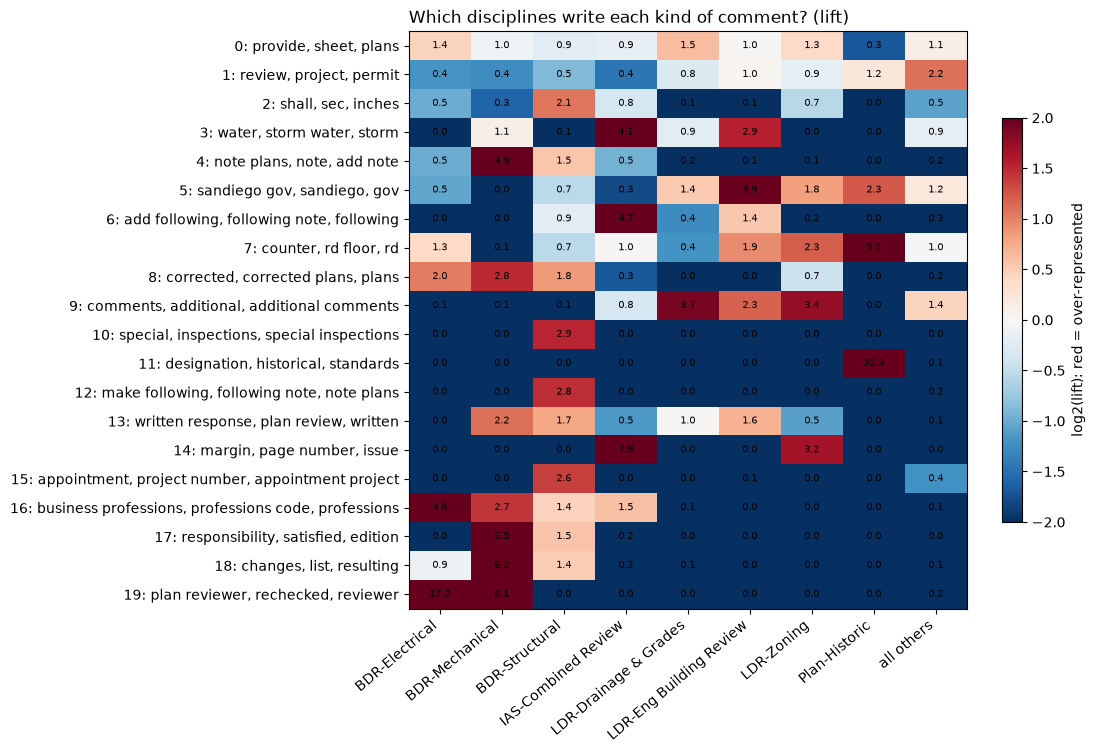

Strongest concentrations (cluster, group), cells with at least 200 comments:
                             lift  comments
cluster DISCIPLINE                         
11      Plan-Historic        32.3    166867
19      BDR-Electrical       17.0     39293
14      IAS-Combined Review   7.9     92313
17      BDR-Mechanical        6.5     39761
18      BDR-Mechanical        6.2     36974
19      BDR-Mechanical        6.1     34655
7       Plan-Historic         5.2     38698
4       BDR-Mechanical        4.9    144323
16      BDR-Electrical        4.8     13592
6       IAS-Combined Review   4.7    139021


In [29]:
recent["cluster"] = recent["norm"].map(pd.Series(labels, index=uniq["norm"]))
cluster_names = [f"{c}: " + ", ".join(summary.loc[c, "top_terms"].split(", ")[:3]) for c in summary.index]


def lift_heatmap(column, top_n, title):
    """Cluster vs. group. Lift = share of the cluster in this group / share of all comments in this group."""
    biggest = recent[column].value_counts().index[:top_n]
    grouped = recent[column].where(recent[column].isin(biggest), "all others")
    lift = pd.crosstab(recent["cluster"], grouped, normalize="index") / grouped.value_counts(normalize=True)
    fig, ax = plt.subplots(figsize=(9, 7.5))
    image = ax.imshow(np.log2(lift.clip(lower=0.25)), cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")   # clip: lift 0 has no log
    ax.set_xticks(range(lift.shape[1]), lift.columns, rotation=40, ha="right")
    ax.set_yticks(range(lift.shape[0]), cluster_names)
    for i in range(lift.shape[0]):
        for j in range(lift.shape[1]):
            ax.text(j, i, f"{lift.iat[i, j]:.1f}", ha="center", va="center", fontsize=7)
    ax.set_title(title, loc="left")
    fig.colorbar(image, label="log2(lift): red = over-represented", shrink=0.7)
    plt.show()

    cells = lift.stack().rename("lift").to_frame()
    cells["comments"] = pd.crosstab(recent["cluster"], grouped).stack()
    print("Strongest concentrations (cluster, group), cells with at least 200 comments:")
    print(cells[cells["comments"] >= 200].sort_values("lift", ascending=False).head(10).round(1).to_string())


lift_heatmap("DISCIPLINE", 8, "Which disciplines write each kind of comment? (lift)")

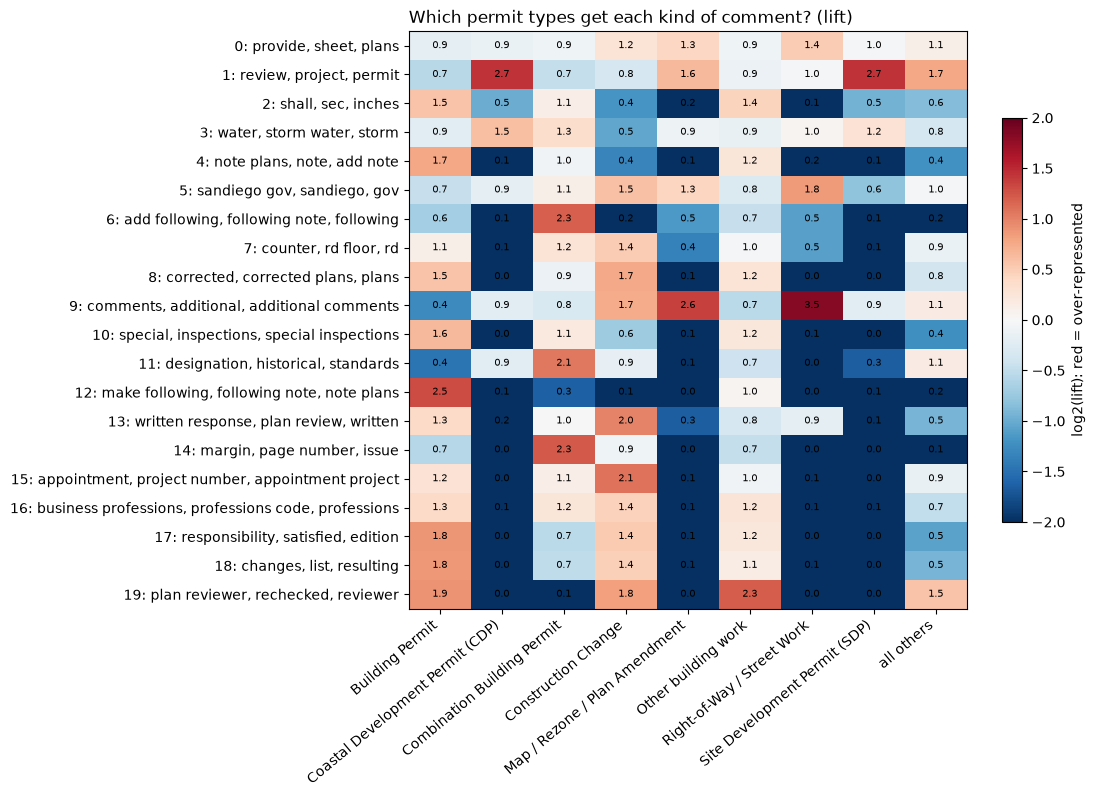

Strongest concentrations (cluster, group), cells with at least 200 comments:
                                          lift  comments
cluster permit_type                                     
9       Right-of-Way / Street Work         3.5     48205
1       Coastal Development Permit (CDP)   2.7    118925
        Site Development Permit (SDP)      2.7     87759
9       Map / Rezone / Plan Amendment      2.6     13989
12      Building Permit                    2.5    113159
14      Combination Building Permit        2.3     71028
19      Other building work                2.3      3667
6       Combination Building Permit        2.3    176416
15      Construction Change                2.1      9015
11      Combination Building Permit        2.1    105008


In [30]:
lift_heatmap("permit_type", 8, "Which permit types get each kind of comment? (lift)")

**What this means.** The standard text is **tied to particular disciplines and permit types**. Strongest concentrations (lift, with comment counts in the table above):
- **By discipline:** the historic-review notices are almost entirely Plan-Historic (cluster 11, lift 32; the same group also leans on e-submittal and web links, cluster 5); "recheck over the counter by any electrical plan reviewer" is Electrical and Mechanical (cluster 19, lift 17 and 6); "note the page number in the margin" is IAS-Combined Review (cluster 14, lift 8), as is water meter and sewer text (cluster 3, lift 4 to 5); the architect-of-record notice, the "changes made?" box and the "list does not include all errors" text are Mechanical (clusters 17, 18, 8, lift 6 to 6.5).
- **By permit type:** Right-of-Way / Street Work leans on "additional comments may follow, please contact" text (cluster 9, lift 3.5, also Map / Rezone at 2.6). Discretionary reviews (SDP and CDP) over-use the "this review is for the discretionary permit only" cluster (cluster 1, lift 2.7). Combination Building Permits get the historic notices (cluster 11, lift 2.1), the page-number request (cluster 14, lift 2.3) and "add the following note" text (cluster 6, lift 2.3). Construction Change reviews carry more of the recheck-by-appointment text (cluster 15, lift 2.1).

In plain terms: boilerplate is mostly a habit of particular review groups, so any fix would be discipline by discipline. **Caveat:** discipline and permit type are tangled together (some disciplines mostly review some permit types), and permit type is our own guess from free text. The 2-file and 10-file runs showed the same pattern, with the same disciplines on top.

**Nearest neighbours.** For three sample comments (picked at random from comments that occur at least 20 times) we list the five most similar comments by cosine similarity (1.0 = identical word weights). This shows how much wording variation sits behind one idea.

In [31]:
for i in uniq[uniq["count"] >= 20].sample(3, random_state=SEED).index:
    sims = cosine_similarity(X[i], X).ravel()
    print(f"\nCOMMENT (occurs {uniq.at[i, 'count']} times): {uniq.at[i, 'example'][:150]}")
    for j in sims.argsort()[::-1][1:6]:     # position 0 is the comment itself
        print(f"   {sims[j]:.2f}  {uniq.at[j, 'example'][:130]}")


COMMENT (occurs 30 times): "Note to Applicant: If the tenant improvement requires minor or no revisions to the existing fire alarm system (the scope of work is limited to the ad
   1.00  "Note to Applicant: If the tenant improvement requires minor or no revisions to the existing fire alarm system (the scope of work 
   0.99  No-plan Fire Alarm Permit Note to Applicant: If the tenant improvement requires minor or no revisions to the existing fire alarm s
   0.99  Note to Applicant: If the tenant improvement requires minor or no revisions to the existing fire alarm system (the scope of work i
   0.98  Re. Comment 12 & 25: Note to Applicant: If the tenant improvement requires minor or no revisions to the existing fire alarm system
   0.98  FYI, Note to Applicant: If the tenant improvement requires minor or no revisions to the existing fire alarm system (the scope of w

COMMENT (occurs 29 times): Sheet 7: Add 1-1/2" Sch 40 conduit item to the legend.
   0.80  Sheet 2: Please add SDM-103 o


COMMENT (occurs 125 times): The centerline of elevator floor buttons shall be no higher than 54 inches (1372 mm) above the finished floor for side approach and 48 inches (1219 mm
   0.93  Elevator floor buttons shall be no higher than 54 inches (1372 mm) above the finished floor for side approach and 48 inches (1219 
   0.93  The centerline of elevator floor buttons shall be no higher than 54 inches (1372 mm) above the finished floor for side approach an
   0.78  The centerline of car control buttons shall be no higher than 48 inches (1372 mm) above the finished floor for side approach and 4
   0.77  The center of the control grip (including coin slots) for some washers and dryers including stacked clothes washers and dryers sha
   0.75  The center of controls grip shall be located no higher than 48 inches (1219 mm, and no lower than 15 inches (381 mm), above the fi


**What this means.** The same idea shows up in many wordings that exact matching cannot join. The elevator-button comment ("The centerline of elevator floor buttons shall be no higher than 54 inches...", 125 times) has near-twins at 0.93 that drop "The centerline of" and a related car-control-buttons version at 0.78. The "Note to Applicant: If the tenant improvement requires minor or no revisions to the existing fire alarm system..." comment (30 times) matches variants with a prefix ("No-plan Fire Alarm Permit", "Re. Comment 12 & 25:", "FYI,") at 0.98 to 0.99. The legend comment ("Sheet 7: Add 1-1/2" Sch 40 conduit item to the legend") only reaches 0.72 to 0.80 with its neighbours, a reminder that short plan-specific requests are hard to group. A fixed template for the standard ones would remove a lot of variation, and similarity search is a cheap way to find such families. (The random sample picks different comments whenever the data changes: with 10 files it found the soils-footings and accessible-water-closet comments.)

## 5. Figures for the presentation

The four charts used in `presentations/comment_patterns.pdf` are made here so they can be regenerated when `N_FILES` changes. The groups below combine the k = 20 clusters by cluster number, **which was done by eye for this run (`N_FILES = 33`, `SEED = 0`)**. If the data or the seed changes, re-read the cluster examples above and update the `GROUPS` and `TEAM_TEXT` dictionaries. Figures are saved to `figures/`.

In [32]:
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
NAVY, ORANGE, GRAY, DARK = "#16284a", "#eb6834", "#b3b7c0", "#16284a"
plt.rcParams.update({"font.size": 15, "text.color": NAVY, "axes.labelcolor": NAVY, "xtick.color": NAVY, "ytick.color": NAVY})


def clean_axes(ax, left=True):
    ax.spines[["top", "right", "bottom"]].set_visible(False)
    ax.spines["left"].set_color("#c9ccd6")
    ax.set_xticks([])
    if not left:
        ax.spines["left"].set_visible(False)


# 1. How often does each comment's wording appear? (share of comments)
n_times = recent["norm"].map(recent["norm"].value_counts())
bins = pd.cut(n_times, [0, 1, 9, 99, np.inf], labels=["Once", "2 to 9\ntimes", "10 to 99\ntimes", "100 or more\ntimes"])
shares = bins.value_counts(normalize=True).sort_index() * 100
fig, ax = plt.subplots(figsize=(6, 4.4))
bars = ax.bar(range(4), shares.values, color=[GRAY, BLUE, BLUE, DARK], width=0.62)
for b, v in zip(bars, shares.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 1, f"{v:.0f}%", ha="center", va="bottom", fontsize=24, fontweight="bold")
ax.set_xticks(range(4), shares.index)
ax.set_yticks([]); ax.set_ylim(0, shares.max() * 1.18)
ax.spines[["top", "right", "left"]].set_visible(False); ax.spines["bottom"].set_color("#c9ccd6")
fig.savefig(FIG / "comments_repeats.png", dpi=200, bbox_inches="tight"); plt.close(fig)
print("repeat buckets (%):", shares.round(1).to_dict())

# 2. Six most repeated comments, with plain-English labels (matched on the start of the example text)
PLAIN = {
    "Please indicate here if any changes": "Tell us if you changed the plans beyond these corrections",
    "This list does not necessarily include": "This list may not include every error; plans need correction",
    "It is the responsibility of architect or engineer of record to ensure": "You are responsible for meeting the latest building codes",
    "All Issue Boxes without check marks": "Mark the page that answers each issue; address every box",
    "To facilitate rechecking, provide an itemized": "Send an itemized written response to each issue",
    "For useful and detailed information": "See DSD's web guide to plan review and permits",
}
top6 = unique_comments(recent).sort_values("count", ascending=False).head(6)
labels6 = []
for ex in top6["example"]:
    hit = [v for k, v in PLAIN.items() if ex.startswith(k)]
    assert hit, f"add a plain-English label for: {ex[:60]}"
    labels6.append(hit[0])
fig, ax = plt.subplots(figsize=(9.75, 2.75))
ax.barh(range(6)[::-1], top6["count"].values, color=BLUE, height=0.62)
ax.set_yticks(range(6)[::-1], labels6)
for y, v in zip(range(6)[::-1], top6["count"].values):
    ax.text(v + top6["count"].max() * 0.01, y, f"{v:,}", va="center", fontsize=17, fontweight="bold")
ax.set_xlim(0, top6["count"].max() * 1.17)
clean_axes(ax)
fig.savefig(FIG / "comments_top_repeated.png", dpi=200, bbox_inches="tight"); plt.close(fig)
print("top 6 counts:", top6["count"].tolist())

# 3. The 20 clusters combined into named groups (cluster numbers chosen by reading the examples above)
GROUPS = {
    "Recheck and response instructions": [7, 8, 13, 14, 15, 17, 18, 19],
    "Standard notices and links": [5, 9, 11],
    'Code rules and "add this note" text': [2, 4, 6, 10, 12, 16],
    "Specific topics (water, property lines...)": [3],
    'Short "provide X on sheet Y" requests': [0],
    "General project and permit comments (mixed)": [1],
}
assert sorted(sum(GROUPS.values(), [])) == list(range(K)), "every cluster must be in exactly one group"
cluster_share = recent["cluster"].value_counts(normalize=True) * 100
group_share = pd.Series({g: cluster_share[c].sum() for g, c in GROUPS.items()})
colors = [ORANGE, ORANGE, BLUE, BLUE, BLUE, GRAY]
fig, ax = plt.subplots(figsize=(7.7, 3.6))
ax.barh(range(6)[::-1], group_share.values, color=colors, height=0.62)
ax.set_yticks(range(6)[::-1], group_share.index)
for y, v in zip(range(6)[::-1], group_share.values):
    ax.text(v + 0.6, y, f"{v:.0f}%", va="center", fontsize=22, fontweight="bold")
ax.set_xlim(0, group_share.max() * 1.2)
clean_axes(ax)
fig.savefig(FIG / "comments_themes.png", dpi=200, bbox_inches="tight"); plt.close(fig)
print("group shares (%):", group_share.round(1).to_dict(), "| standard text (orange):", round(group_share.iloc[:2].sum(), 1))

# 4. Who writes which standard text: team's share of a cluster vs the team's share of all comments
TEAM_TEXT = [
    ("Historic-review notices\n(Historic team)", 11, "Plan-Historic"),
    ('"Recheck over the counter" notice\n(Electrical team)', 19, "BDR-Electrical"),
    ("Water and sewer text\n(Combined Review team)", 3, "IAS-Combined Review"),
    ('"Note the page number" request\n(Combined Review team)', 14, "IAS-Combined Review"),
    ("Code-responsibility notice\n(Mechanical team)", 17, "BDR-Mechanical"),
]
team_overall = recent["DISCIPLINE"].value_counts(normalize=True) * 100
by_team = [(lab, (recent.loc[recent["cluster"] == c, "DISCIPLINE"] == t).mean() * 100, team_overall[t]) for lab, c, t in TEAM_TEXT]
fig, ax = plt.subplots(figsize=(7.8, 4.5))
for i, (lab, of_text, of_all) in enumerate(by_team[::-1]):
    ax.barh(i + 0.2, of_text, height=0.36, color=ORANGE)
    ax.barh(i - 0.2, of_all, height=0.36, color=GRAY)
    ax.text(of_text + 1, i + 0.2, f"{of_text:.0f}%", va="center", fontsize=20, fontweight="bold")
    ax.text(of_all + 1, i - 0.2, f"{of_all:.0f}%", va="center", fontsize=17, color="#6b7280")
ax.set_yticks(range(len(by_team)), [b[0] for b in by_team[::-1]])
ax.set_xlim(0, 100)
clean_axes(ax)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color=GRAY)],
          labels=["Share of this text written by the team", "Team's share of all comments"],
          loc="upper center", bbox_to_anchor=(0.4, 0.0), frameon=False, fontsize=14)
fig.savefig(FIG / "comments_who_writes.png", dpi=200, bbox_inches="tight"); plt.close(fig)
print("who writes (team share of text, team share of all):", [(b[0].split(chr(10))[0], round(b[1]), round(b[2])) for b in by_team])


repeat buckets (%): {'Once': 4.2, '2 to 9\ntimes': 46.1, '10 to 99\ntimes': 9.6, '100 or more\ntimes': 40.1}


top 6 counts: [65101, 54046, 40351, 33493, 27995, 26222]
group shares (%): {'Recheck and response instructions': 9.3, 'Standard notices and links': 6.3, 'Code rules and "add this note" text': 20.8, 'Specific topics (water, property lines...)': 4.6, 'Short "provide X on sheet Y" requests': 44.0, 'General project and permit comments (mixed)': 15.0} | standard text (orange): 15.6


who writes (team share of text, team share of all): [('Historic-review notices', 99, 3), ('"Recheck over the counter" notice', 49, 3), ('Water and sewer text', 46, 11), ('"Note the page number" request', 90, 11), ('Code-responsibility notice', 46, 7)]


## 6. Summary (exploratory and preliminary)

**What we did.** Loaded all 33 chunks (16,493,847 comments after dropping 25 exact duplicates), derived permit type from `SCOPE` (1.3% of comments left `Unknown`), kept review years 2010 and later (10,965,475 comments, 2,568,900 distinct after normalizing), then looked at exact repeats and at TF-IDF + KMeans clusters (k = 20, learned from the 600,000 most common distinct comments and extended to the rest). Earlier runs on 2 and 10 chunks gave the same picture in most respects; the differences are noted below.

**What we learned.**
1. **Almost all comments are repeated text.** 96% of comments repeat (53% with 2 files, 70% with 10), 50% appear 10 or more times (38%, 45%), and all 20 most common comments are boilerplate. Half of all comments come from about 2% of the distinct ones (52,085).
2. **Themes.**
   - Recheck and response text (about 9% of comments, only about 20,000 distinct comments).
   - Other standard notices (web links and e-submittal, "additional comments may follow", historic review, about 6%).
   - Code citations, special-inspection notes and "add the following note to the plans" (about 21%).
   - Topic cluster: water and sewer (about 5%).
   - Short "provide X on sheet Y" requests (44%) and a mixed group of general project and permit comments (15%) with no shared theme.
3. **The text is tied to disciplines and permit types.** For example, historic notices sit in Plan-Historic (99% of that cluster), "recheck over the counter by any electrical plan reviewer" in Electrical and Mechanical, and the "note the page number" request in IAS-Combined Review (90%). Right-of-way and map/rezone reviews are mostly free-form.
4. **Ideas to explore (hypotheses, not findings).** Recheck and response instructions could be delivered by the portal instead of repeated as comments. Repeated requests for specific plan content (water and sewer fee payer, water heater data, earthwork and impervious-area tables, energy notes) could become checklist items. Many near-duplicate wordings could be replaced by one standard comment.

**What changed from 10 files to 33.** Repetition went up again (70% to 96% of comments repeat; 45% to 50% appear 10+ times) and concentration too (3% to 2% of wordings cover half). The top-N coverage (3.1% / 11% / 26% / 42%), the ranking of the most common comments, the discipline and permit-type mix, the share of `Unknown` permit types (1.3%), the cleared-flag rate (38%) and the near-zero silhouette did not change. Cluster sizes and numbering changed a lot (the biggest cluster went from 35% to 44%, the standard-text share from about 18% to about 16%, with recheck and response text falling from about 11% to 9%), so the exact cluster percentages should be read as approximate. The year pattern is the same (peak in 2019, sharp drop after 2021).

**Limitations.**
- **Cluster shortcut:** to fit in memory, clusters are learned from the 600,000 most common distinct comments (68% of all comments); rarer wordings are assigned to the nearest cluster. Cluster numbers and percentages are still approximate.
- **Old and missing data:** we kept 2010 onward; 1,850,107 comments with no year (cancelled or never-assigned reviews) are left out; volume falls sharply after 2021, possibly because of a system change (to confirm with DSD).
- **`IS_CLEARED_IND` is unreliable:** only 43% of comments in Closed reviews are marked cleared, so we cannot study which comments were resolved. `REVIEW_CYCLE_ID` is a global ID, so review rounds per project are not given directly.
- **Noisy methods:** permit type is guessed from free text; silhouette is about 0, so clusters are soft; the two biggest clusters are catch-alls; normalization misses rewordings and typos; cluster themes were named by eye.
- The data is raw and unvalidated, and nothing here is an official City or DSD finding.

**Suggested next steps.**
- Sentence embeddings with HDBSCAN to group rewordings without choosing k, and compare against the TF-IDF clusters here.
- Repeated comments across cycles on the same project: derive the cycle order, then check which comments come back.
- Comment themes versus review time and number of cycles, by joining to the Reviews extract.
- Ask DSD which standard texts come from templates, what changed after 2021, and how P2K projects link to current records.